In [1]:

#ZEEMAN SPLITTING

def zeeman_splitting(B, wavelength):
    """
    Calculate the characteristic Zeeman wavelength splitting.constructive interference

    Parameters
    ----------
    B : Magnetic field strength in Gauss.

    lambda : Unperturbed wavelength in Angstrom.

    Returns
    -------
    delta_lambda_B : float
        Characteristic Zeeman displacement in Angstrom.
    """

    delta_lambda_B = 4.67e-13 * B * wavelength**2

    return delta_lambda_B


# Example for HD 101065
B = 2300             # Magnetic field in Gauss
wavelength = 16000   # Wavelength in Angstrom

result = zeeman_splitting(B, wavelength)

print("Magnetic field:", B, "G")
print("Wavelength:", wavelength, "Angstrom")
print("Zeeman splitting:", result, "Angstrom")


Magnetic field: 2300 G
Wavelength: 16000 Angstrom
Zeeman splitting: 0.27496960000000004 Angstrom


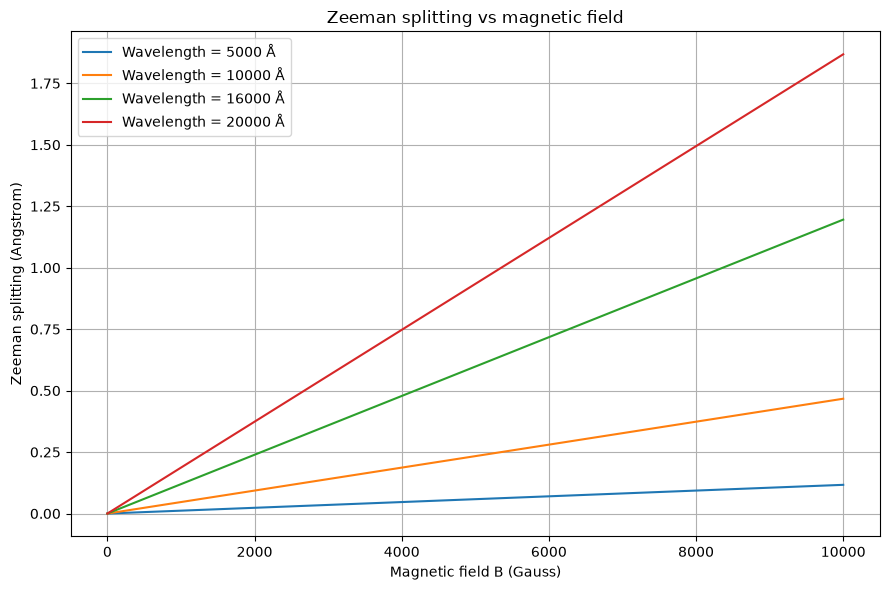

In [2]:
#zeeman splitting vs B

import numpy as np
import matplotlib.pyplot as plt

# Equation 1.5
def zeeman_splitting(B, wavelength):
    return 4.67e-13 * B * wavelength**2


# Magnetic field range: 0 to 10000 Gauss
B_values = np.linspace(0, 10000, 500)

# Different wavelengths
wavelengths = [5000, 10000, 16000, 20000]

plt.figure(figsize=(9, 6))

for wavelength in wavelengths:

    delta_lambda = zeeman_splitting(B_values, wavelength)

    plt.plot(
        B_values,
        delta_lambda,
        label=f"Wavelength = {wavelength} Å"
    )

plt.xlabel("Magnetic field B (Gauss)")
plt.ylabel("Zeeman splitting (Angstrom)")
plt.title("Zeeman splitting vs magnetic field")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


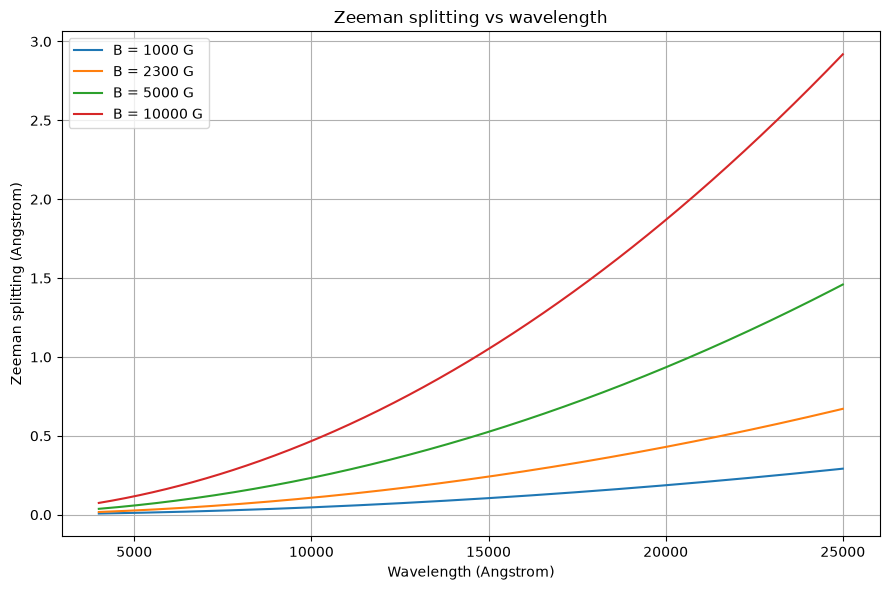

In [3]:
#zeeman splitting vs lambda


import numpy as np
import matplotlib.pyplot as plt

def zeeman_splitting(B, wavelength):
    return 4.67e-13 * B * wavelength**2


# Wavelengths from optical to infrared
wavelength_values = np.linspace(4000, 25000, 500)

# Different magnetic field strengths
magnetic_fields = [1000, 2300, 5000, 10000]

plt.figure(figsize=(9, 6))

for B in magnetic_fields:

    delta_lambda = zeeman_splitting(
        B, wavelength_values
    )

    plt.plot(
        wavelength_values,
        delta_lambda,
        label=f"B = {B} G"
    )

plt.xlabel("Wavelength (Angstrom)")
plt.ylabel("Zeeman splitting (Angstrom)")
plt.title("Zeeman splitting vs wavelength")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [4]:
#relative strengths


from sympy import S
from sympy.physics.wigner import wigner_3j


def relative_strength(J_l, J_u, M_l, M_u, q):
    """
    Calculate the relative strength of a Zeeman component
    using equation 1.6.

    J_l : lower level total angular momentum
    J_u : upper level total angular momentum
    M_l : lower level magnetic quantum number
    M_u : upper level magnetic quantum number
    q   : polarization component (0, +1, -1)
    """

    # Convert numbers to exact SymPy quantities
    J_l = S(str(J_l))
    J_u = S(str(J_u))
    M_l = S(str(M_l))
    M_u = S(str(M_u))
    q = S(str(q))

    # Calculate the Wigner 3-j symbol
    W = wigner_3j(
        J_u, J_l, 1,
        -M_u, M_l, -q
    )

    # Equation 1.6
    T = 3 * W**2

    return float(T)


# Example: J_l = 1 and J_u = 2
J_l = 1
J_u = 2

M_l = 0
M_u = 1
q = -1

strength = relative_strength(
    J_l, J_u, M_l, M_u, q
)

print("Relative strength:", strength)


Relative strength: 0.3


In [5]:
#allowed zeeman


from sympy import S
from sympy.physics.wigner import wigner_3j


def magnetic_quantum_numbers(J):
    """
    Generate all allowed M values for angular momentum J.
    Works for integer and half-integer J.
    """

    J = S(str(J))

    return [-J + k for k in range(int(2 * J) + 1)]


def relative_strength(J_l, J_u, M_l, M_u, q):

    W = wigner_3j(
        J_u, J_l, 1,
        -M_u, M_l, -q
    )

    return float(3 * W**2)


def calculate_components(J_l, J_u):

    J_l = S(str(J_l))
    J_u = S(str(J_u))

    # Electric-dipole angular momentum selection rule
    if abs(J_u - J_l) > 1 or (J_l == 0 and J_u == 0):
        raise ValueError("Forbidden electric-dipole J transition")

    M_l_values = magnetic_quantum_numbers(J_l)
    M_u_values = magnetic_quantum_numbers(J_u)

    components = []

    for M_l in M_l_values:

        for M_u in M_u_values:

            q = M_l - M_u

            if q not in [-1, 0, 1]:
                continue

            T = relative_strength(
                J_l, J_u, M_l, M_u, q
            )

            if T > 0:

                components.append({
                    "M_l": M_l,
                    "M_u": M_u,
                    "q": int(q),
                    "strength": T
                })

    return components


# Example
components = calculate_components(1, 2)

print("Number of components:", len(components))

for component in components:
    print(component)


Number of components: 9
{'M_l': -1, 'M_u': -2, 'q': 1, 'strength': 0.6}
{'M_l': -1, 'M_u': -1, 'q': 0, 'strength': 0.3}
{'M_l': -1, 'M_u': 0, 'q': -1, 'strength': 0.1}
{'M_l': 0, 'M_u': -1, 'q': 1, 'strength': 0.3}
{'M_l': 0, 'M_u': 0, 'q': 0, 'strength': 0.4}
{'M_l': 0, 'M_u': 1, 'q': -1, 'strength': 0.3}
{'M_l': 1, 'M_u': 0, 'q': 1, 'strength': 0.1}
{'M_l': 1, 'M_u': 1, 'q': 0, 'strength': 0.3}
{'M_l': 1, 'M_u': 2, 'q': -1, 'strength': 0.6}


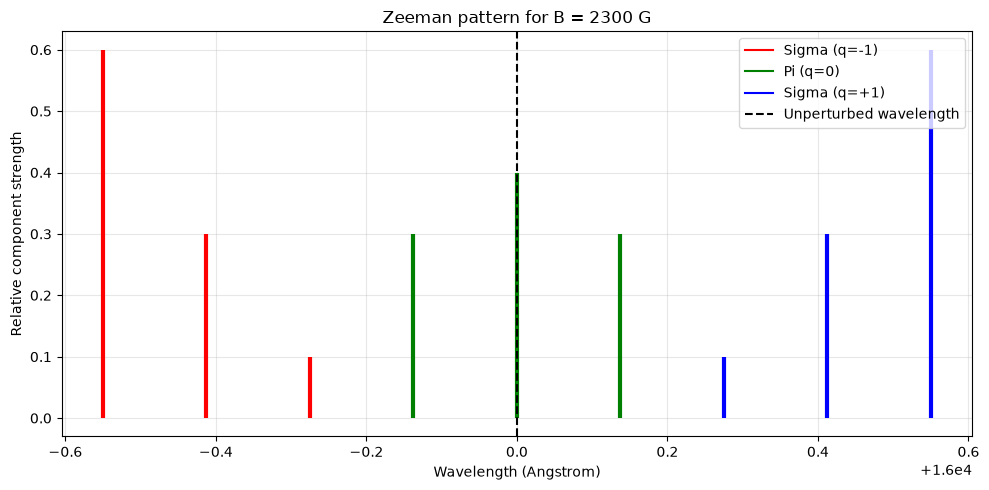

Wavelength = 15999.45006 A, Shift = -0.54994 A, q = -1, Strength = 0.600
Wavelength = 15999.58755 A, Shift = -0.41245 A, q = -1, Strength = 0.300
Wavelength = 15999.72503 A, Shift = -0.27497 A, q = -1, Strength = 0.100
Wavelength = 15999.86252 A, Shift = -0.13748 A, q = +0, Strength = 0.300
Wavelength = 16000.00000 A, Shift = +0.00000 A, q = +0, Strength = 0.400
Wavelength = 16000.13748 A, Shift = +0.13748 A, q = +0, Strength = 0.300
Wavelength = 16000.27497 A, Shift = +0.27497 A, q = +1, Strength = 0.100
Wavelength = 16000.41245 A, Shift = +0.41245 A, q = +1, Strength = 0.300
Wavelength = 16000.54994 A, Shift = +0.54994 A, q = +1, Strength = 0.600


In [8]:
#zeeman pattern


import numpy as np
import matplotlib.pyplot as plt

from sympy import S
from sympy.physics.wigner import wigner_3j


# Equation 1.5
def zeeman_splitting(B, wavelength):
    return 4.67e-13 * B * wavelength**2


# Equation 1.6
def relative_strength(J_l, J_u, M_l, M_u, q):

    W = wigner_3j(
        J_u, J_l, 1,
        -M_u, M_l, -q
    )

    return float(3 * W**2)


def magnetic_quantum_numbers(J):

    return [-J + k for k in range(int(2 * J) + 1)]


def zeeman_pattern(J_l, J_u, g_l, g_u, B, wavelength):

    J_l = S(str(J_l))
    J_u = S(str(J_u))

    if abs(J_u - J_l) > 1 or (J_l == 0 and J_u == 0):
        raise ValueError("Forbidden electric-dipole J transition")

    M_l_values = magnetic_quantum_numbers(J_l)
    M_u_values = magnetic_quantum_numbers(J_u)

    delta_B = zeeman_splitting(B, wavelength)

    components = []

    for M_l in M_l_values:

        for M_u in M_u_values:

            q = M_l - M_u

            if q not in [-1, 0, 1]:
                continue

            T = relative_strength(
                J_l, J_u, M_l, M_u, q
            )

            if T == 0:
                continue

            # Equation 1.4 (positions)
            shift = (
                g_l * float(M_l)
                - g_u * float(M_u)
            ) * delta_B

            component_wavelength = wavelength + shift

            components.append({
                "wavelength": component_wavelength,
                "shift": shift,
                "strength": T,
                "q": int(q)
            })

    return components



# Example parameters

J_l = 1
J_u = 2

g_l = 1.0
g_u = 1.5

B = 2300
wavelength = 16000

components = zeeman_pattern(
    J_l, J_u, g_l, g_u, B, wavelength
)


# Plot

plt.figure(figsize=(10, 5))

colors = {
    -1: "red",
     0: "green",
     1: "blue"
}

labels = {
    -1: "Sigma (q=-1)",
     0: "Pi (q=0)",
     1: "Sigma (q=+1)"
}

for q in [-1, 0, 1]:

    subset = [c for c in components if c["q"] == q]

    for c in subset:

        plt.vlines(
            c["wavelength"],
            0,
            c["strength"],
            color=colors[q],
            linewidth=3
        )

    # Add one legend entry per group
    plt.plot([], [], color=colors[q], label=labels[q])

plt.axvline(
    wavelength,
    color="black",
    linestyle="--",
    label="Unperturbed wavelength"
)

plt.xlabel("Wavelength (Angstrom)")
plt.ylabel("Relative component strength")
plt.title("Zeeman pattern for B = 2300 G")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Print component information
for c in sorted(components, key=lambda x: x["wavelength"]):

    print(
        f"Wavelength = {c['wavelength']:.5f} A, "
        f"Shift = {c['shift']:+.5f} A, "
        f"q = {c['q']:+d}, "
        f"Strength = {c['strength']:.3f}"
    )


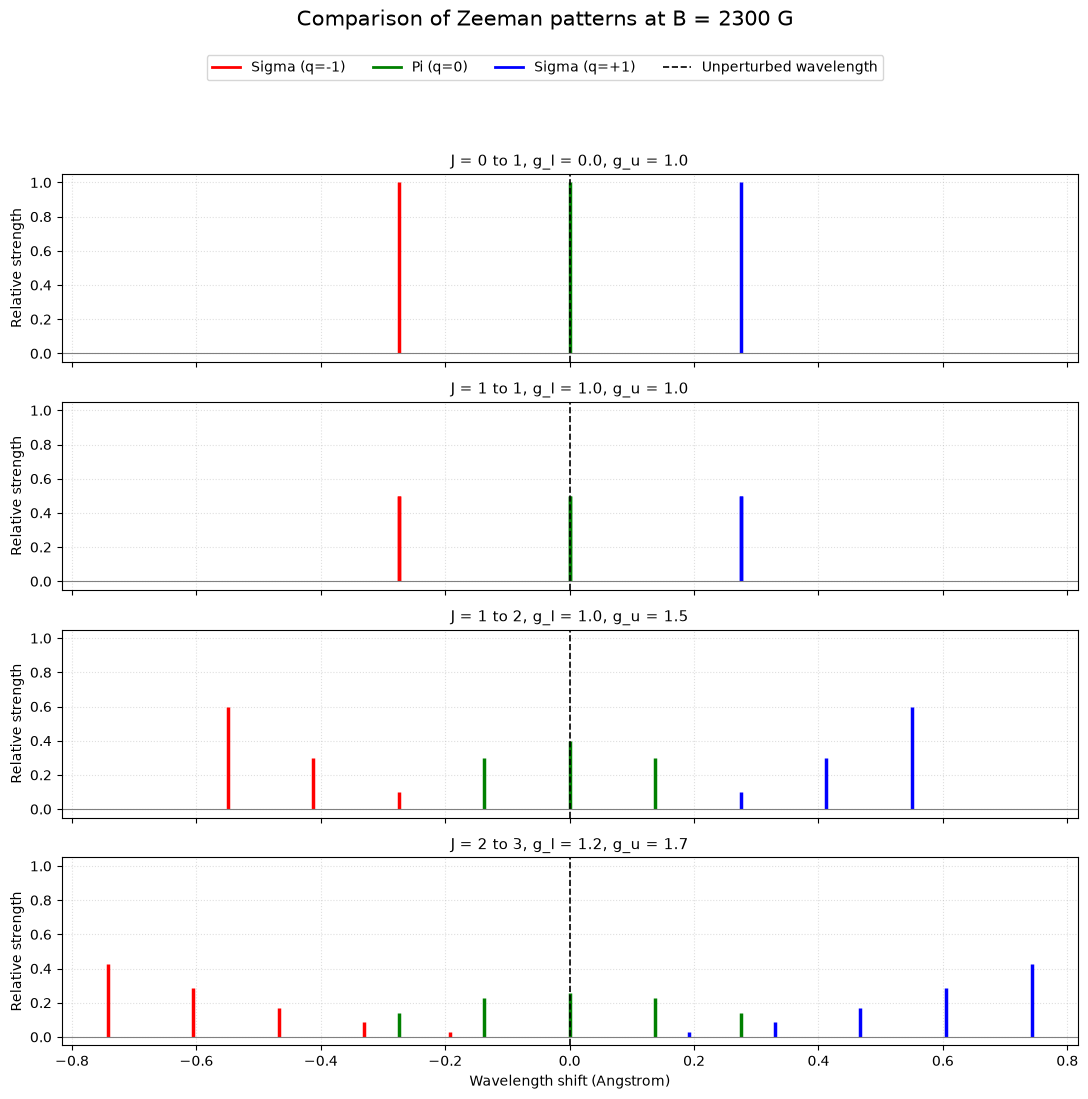

In [9]:

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Illustrative atomic transitions
transitions = [
    (0, 1, 0.0, 1.0),
    (1, 1, 1.0, 1.0),
    (1, 2, 1.0, 1.5),
    (2, 3, 1.2, 1.7)
]

B = 2300
wavelength = 16000

# Colours for the Zeeman components
colors = {
    -1: "red",
     0: "green",
     1: "blue"
}

# Labels for the legend
labels = {
    -1: "Sigma (q=-1)",
     0: "Pi (q=0)",
     1: "Sigma (q=+1)"
}

# Create four subplots
fig, axes = plt.subplots(
    4, 1,
    figsize=(11, 11),
    sharex=True,
    sharey=True
)

# Loop over the transitions
for ax, (Jl, Ju, gl, gu) in zip(axes, transitions):

    components = zeeman_pattern(
        Jl, Ju, gl, gu, B, wavelength
    )

    # Plot each component with its corresponding colour
    for c in components:

        q = c["q"]

        ax.vlines(
            c["shift"],
            0,
            c["strength"],
            color=colors[q],
            linewidth=2.5
        )

    # Original wavelength (zero shift)
    ax.axvline(
        0,
        color="black",
        linestyle="--",
        linewidth=1.2
    )

    # Horizontal reference line
    ax.axhline(
        0,
        color="gray",
        linewidth=0.8
    )

    # Title for each subplot
    ax.set_title(
        f"J = {Jl} to {Ju}, "
        f"g_l = {gl}, g_u = {gu}",
        fontsize=11
    )

    ax.set_ylabel("Relative strength")

    # Add grid
    ax.grid(
        True,
        linestyle=":",
        alpha=0.4
    )

    # Keep the grid behind the components
    ax.set_axisbelow(True)

# Create legend entries
legend_elements = [
    Line2D([0], [0], color="red", lw=2,
           label="Sigma (q=-1)"),

    Line2D([0], [0], color="green", lw=2,
           label="Pi (q=0)"),

    Line2D([0], [0], color="blue", lw=2,
           label="Sigma (q=+1)"),

    Line2D([0], [0], color="black", lw=1.2,
           linestyle="--",
           label="Unperturbed wavelength")
]

# One legend for the whole figure
fig.legend(
    handles=legend_elements,
    loc="upper center",
    ncol=4,
    bbox_to_anchor=(0.5, 0.96)
)

# Common x-axis label
axes[-1].set_xlabel("Wavelength shift (Angstrom)")

# Main figure title
fig.suptitle(
    f"Comparison of Zeeman patterns at B = {B} G",
    fontsize=15,
    y=0.995
)

plt.tight_layout(rect=[0, 0, 1, 0.91])
plt.show()



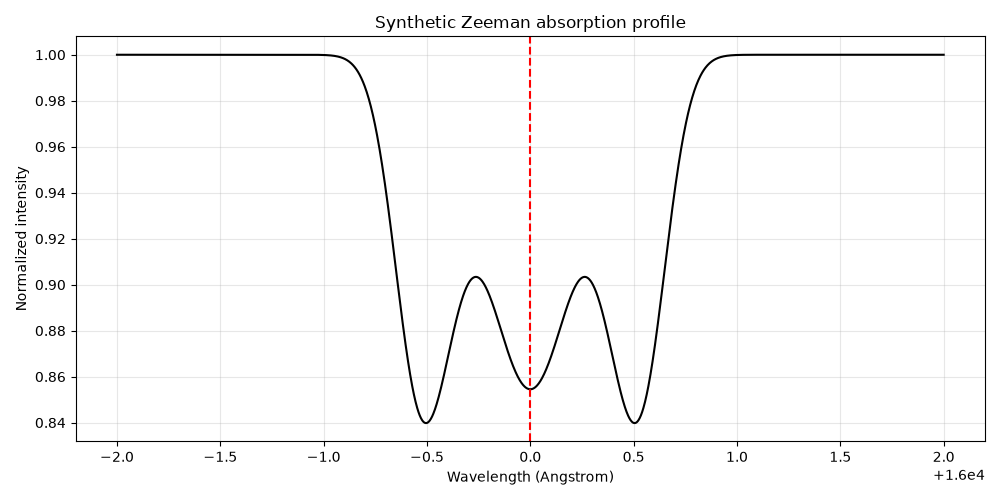

In [23]:
#synthetic absorption lines

import numpy as np
import matplotlib.pyplot as plt

# Parameters
B = 2300
wavelength = 16000

J_l = 1
J_u = 2

g_l = 1.0
g_u = 1.5

sigma = 0.12  # Gaussian width in Angstrom
depth = 0.6   # Approximate absorption depth

# Calculate Zeeman components
components = zeeman_pattern(
    J_l, J_u, g_l, g_u, B, wavelength
)

# Wavelength grid
wave = np.linspace(
    wavelength - 2,
    wavelength + 2,
    2000
)

# Start with continuum intensity = 1
profile = np.zeros_like(wave)

total_strength = sum(c["strength"] for c in components)

# Add Gaussian contributions
for c in components:

    gaussian = np.exp(
        -(wave - c["wavelength"])**2 /
        (2 * sigma**2)
    )

    profile += c["strength"] * gaussian / total_strength

# Approximate normalized intensity
intensity = 1 - depth * profile

plt.figure(figsize=(10, 5))

plt.plot(wave, intensity, color="black")

plt.axvline(wavelength, color="red", linestyle="--")

plt.xlabel("Wavelength (Angstrom)")
plt.ylabel("Normalized intensity")
plt.title("Synthetic Zeeman absorption profile")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


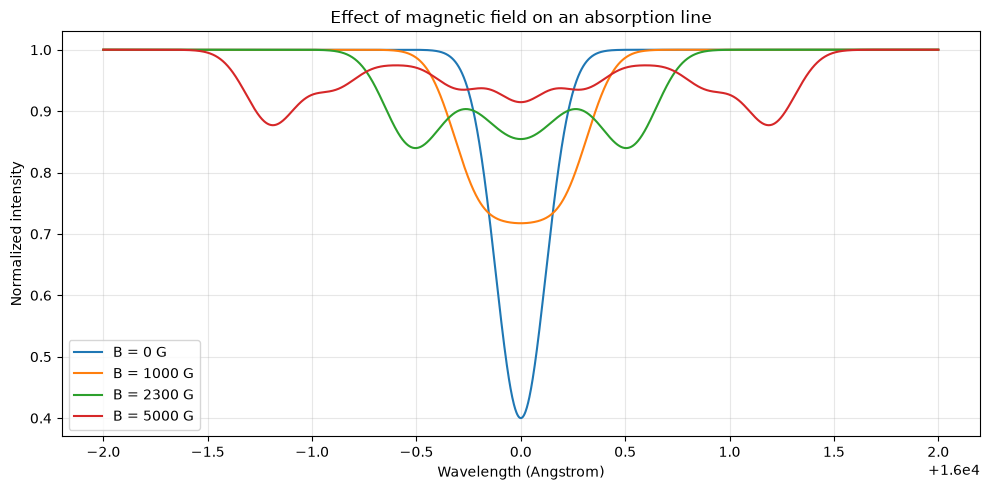

In [11]:
#B vs non-B spectra


import numpy as np
import matplotlib.pyplot as plt

wavelength = 16000
sigma = 0.12
depth = 0.6

wave = np.linspace(15998, 16002, 2000)

B_values = [0, 1000, 2300, 5000]

plt.figure(figsize=(10, 5))

for B in B_values:

    components = zeeman_pattern(
        1, 2, 1.0, 1.5, B, wavelength
    )

    total_strength = sum(c["strength"] for c in components)

    profile = np.zeros_like(wave)

    for c in components:

        profile += (
            c["strength"] / total_strength
            * np.exp(
                -(wave - c["wavelength"])**2
                / (2 * sigma**2)
            )
        )

    intensity = 1 - depth * profile

    plt.plot(wave, intensity, label=f"B = {B} G")

plt.xlabel("Wavelength (Angstrom)")
plt.ylabel("Normalized intensity")
plt.title("Effect of magnetic field on an absorption line")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [12]:
#effective lande factor calculation

def effective_lande(J_l, J_u, g_l, g_u):

    g_eff = (
        (g_u + g_l) / 2
        +
        (g_u - g_l) / 4
        * (
            J_u * (J_u + 1)
            - J_l * (J_l + 1)
        )
    )

    return g_eff


# Example
J_l = 1
J_u = 2

g_l = 1.0
g_u = 1.5

g_eff = effective_lande(J_l, J_u, g_l, g_u)

print("Effective Lande factor:", g_eff)


Effective Lande factor: 1.75


True magnetic field: 2300 G
Recovered magnetic field: 2300 G


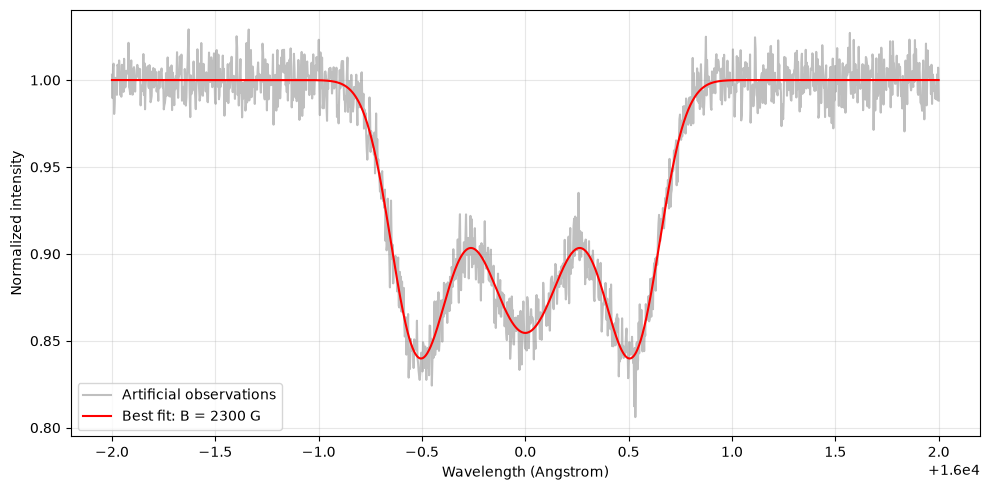

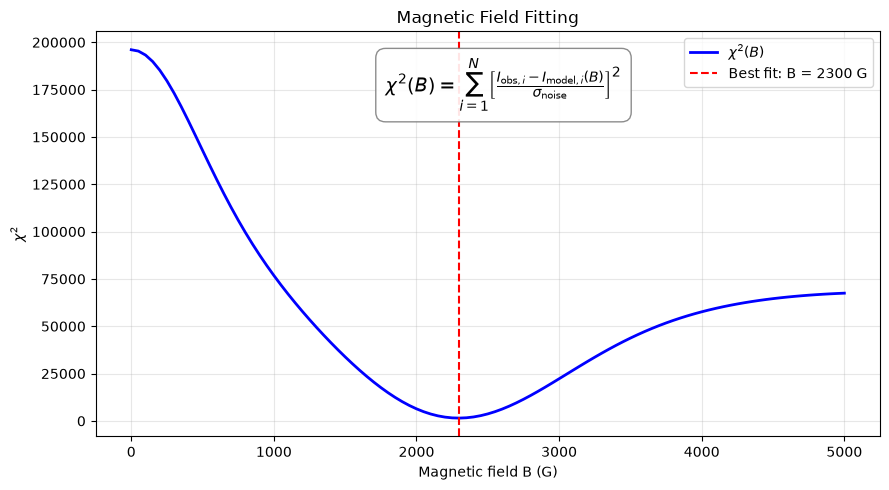

In [13]:
# artificial observations, noise, and best-fitting magnetic field

import numpy as np
import matplotlib.pyplot as plt



wavelength = 16000
wave = np.linspace(15998, 16002, 1500)

J_l, J_u = 1, 2
g_l, g_u = 1.0, 1.5

sigma = 0.12
depth = 0.6


def synthetic_spectrum(B):

    components = zeeman_pattern(
        J_l, J_u, g_l, g_u, B, wavelength
    )

    total = sum(c["strength"] for c in components)

    profile = np.zeros_like(wave)

    for c in components:

        profile += (
            c["strength"] / total
            * np.exp(
                -(wave - c["wavelength"])**2
                / (2 * sigma**2)
            )
        )

    return 1 - depth * profile


# Create artificial observations
rng = np.random.default_rng(42)

B_true = 2300

observed = synthetic_spectrum(B_true)

noise = rng.normal(0, 0.01, size=len(wave))

observed_noisy = observed + noise


# Try different magnetic fields
B_grid = np.arange(0, 5001, 50)

chi_squared = []

for B in B_grid:

    model = synthetic_spectrum(B)

    chi2 = np.sum(
        ((observed_noisy - model) / 0.01)**2
    )

    chi_squared.append(chi2)


# Best-fitting field
best_index = np.argmin(chi_squared)

B_best = B_grid[best_index]

print("True magnetic field:", B_true, "G")
print("Recovered magnetic field:", B_best, "G")


# Plot observed and fitted spectrum
plt.figure(figsize=(10, 5))

plt.plot(
    wave,
    observed_noisy,
    color="gray",
    alpha=0.5,
    label="Artificial observations"
)

plt.plot(
    wave,
    synthetic_spectrum(B_best),
    color="red",
    label=f"Best fit: B = {B_best} G"
)

plt.xlabel("Wavelength (Angstrom)")
plt.ylabel("Normalized intensity")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Plot chi-squared

# Plot chi-squared versus magnetic field
plt.figure(figsize=(9, 5))

plt.plot(
    B_grid,
    chi_squared,
    color="blue",
    linewidth=2,
    label=r"$\chi^2(B)$"
)

plt.axvline(
    B_best,
    color="red",
    linestyle="--",
    label=f"Best fit: B = {B_best} G"
)

# Chi-squared equation
equation = (
    r"$\chi^2(B) = \sum_{i=1}^{N}"
    r"\left[\frac{I_{\mathrm{obs},i}"
    r"-I_{\mathrm{model},i}(B)}"
    r"{\sigma_{\mathrm{noise}}}\right]^2$"
)

# Add equation inside the plot
plt.text(
    0.52, 0.85,
    equation,
    transform=plt.gca().transAxes,
    fontsize=14,
    ha="center",
    bbox=dict(
        facecolor="white",
        edgecolor="gray",
        alpha=0.9,
        boxstyle="round,pad=0.5"
    )
)

plt.xlabel("Magnetic field B (G)")
plt.ylabel(r"$\chi^2$")
plt.title("Magnetic Field Fitting")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



In [14]:
%pip install ipympl

Note: you may need to restart the kernel to use updated packages.


In [15]:
%matplotlib widget

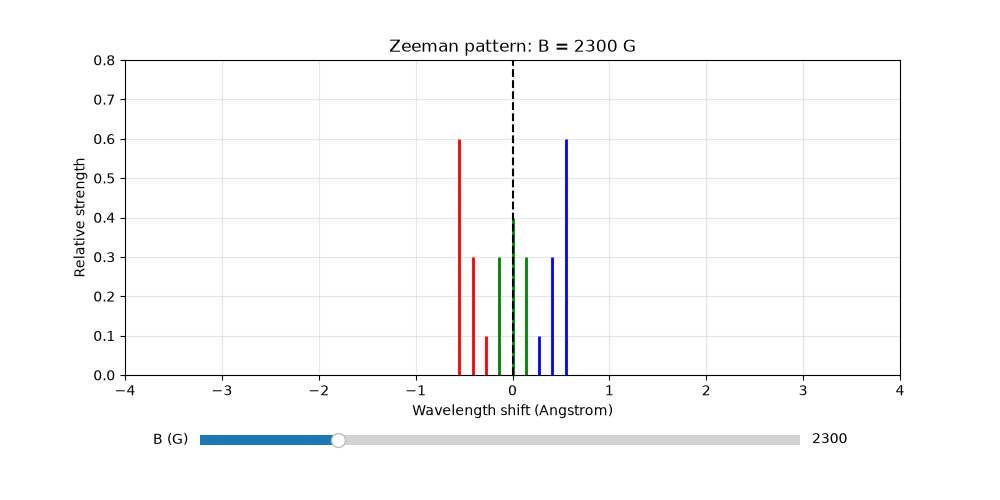

In [16]:

import matplotlib.pyplot as plt
from matplotlib.widgets import Slider

# Fixed atomic transition
Jl, Ju = 1, 2
gl, gu = 1.0, 1.5
wavelength = 16000

colors = {-1: "red", 0: "green", 1: "blue"}

fig, ax = plt.subplots(figsize=(10, 5))
plt.subplots_adjust(bottom=0.25)

# Slider for magnetic field
slider_ax = plt.axes([0.2, 0.1, 0.6, 0.04])

B_slider = Slider(
    slider_ax,
    "B (G)",
    valmin=0,
    valmax=10000,
    valinit=2300,
    valstep=100
)

def update(B):
    ax.clear()

    components = zeeman_pattern(
        Jl, Ju, gl, gu, B, wavelength
    )

    for c in components:
        ax.vlines(
            c["shift"],
            0,
            c["strength"],
            color=colors[c["q"]],
            linewidth=2
        )

    ax.axvline(0, color="black", linestyle="--")
    ax.set_xlim(-4, 4)
    ax.set_ylim(0, 0.8)
    ax.set_xlabel("Wavelength shift (Angstrom)")
    ax.set_ylabel("Relative strength")
    ax.set_title(f"Zeeman pattern: B = {B:.0f} G")
    ax.grid(alpha=0.3)

    fig.canvas.draw_idle()

B_slider.on_changed(update)

update(2300)
plt.show()


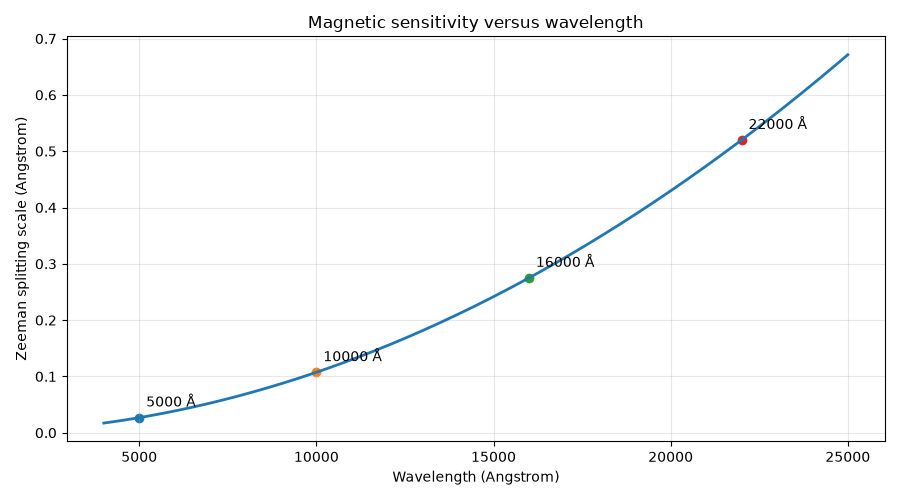

In [17]:

import numpy as np
import matplotlib.pyplot as plt

B = 2300

wavelengths = np.linspace(4000, 25000, 500)

splitting = 4.67e-13 * B * wavelengths**2

plt.figure(figsize=(9, 5))

plt.plot(wavelengths, splitting, linewidth=2)

# Reference wavelengths
for wl in [5000, 10000, 16000, 22000]:
    delta = 4.67e-13 * B * wl**2

    plt.scatter(wl, delta)
    plt.annotate(
        f"{wl} Å",
        (wl, delta),
        xytext=(5, 8),
        textcoords="offset points"
    )

plt.xlabel("Wavelength (Angstrom)")
plt.ylabel("Zeeman splitting scale (Angstrom)")
plt.title("Magnetic sensitivity versus wavelength")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


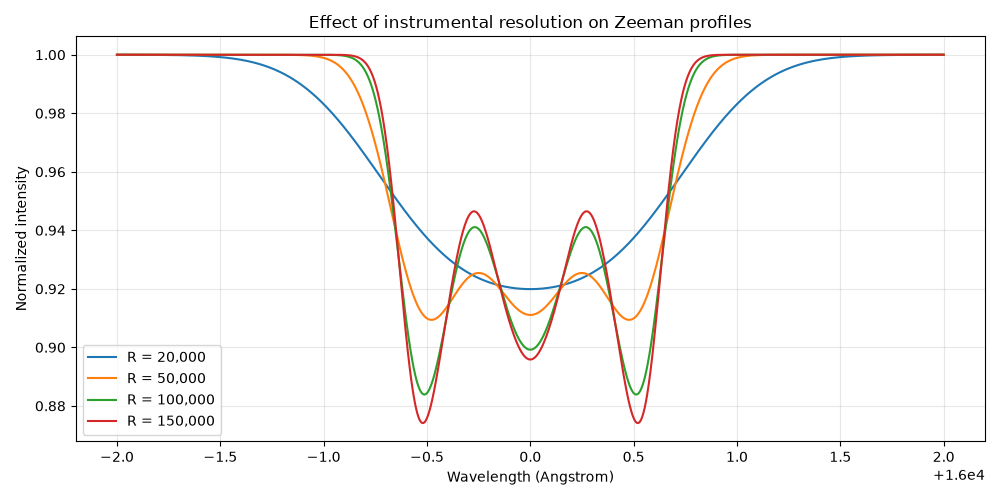

In [18]:
#instrumental broadening


import numpy as np
import matplotlib.pyplot as plt

wavelength = 16000
wave = np.linspace(15998, 16002, 2000)

B = 2300
components = zeeman_pattern(
    1, 2, 1.0, 1.5, B, wavelength
)

R_values = [20000, 50000, 100000, 150000]

sigma_intrinsic = 0.08
depth = 0.6

total = sum(c["strength"] for c in components)

plt.figure(figsize=(10, 5))

for R in R_values:

    fwhm_inst = wavelength / R

    sigma_inst = fwhm_inst / (
        2 * np.sqrt(2 * np.log(2))
    )

    # Gaussian convolution:
    # variances add
    sigma_total = np.sqrt(
        sigma_intrinsic**2 + sigma_inst**2
    )

    profile = np.zeros_like(wave)

    for c in components:
        profile += (
            c["strength"] / total
            * sigma_intrinsic / sigma_total
            * np.exp(
                -(wave - c["wavelength"])**2
                / (2 * sigma_total**2)
            )
        )

    intensity = 1 - depth * profile

    plt.plot(wave, intensity, label=f"R = {R:,}")

plt.xlabel("Wavelength (Angstrom)")
plt.ylabel("Normalized intensity")
plt.title("Effect of instrumental resolution on Zeeman profiles")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


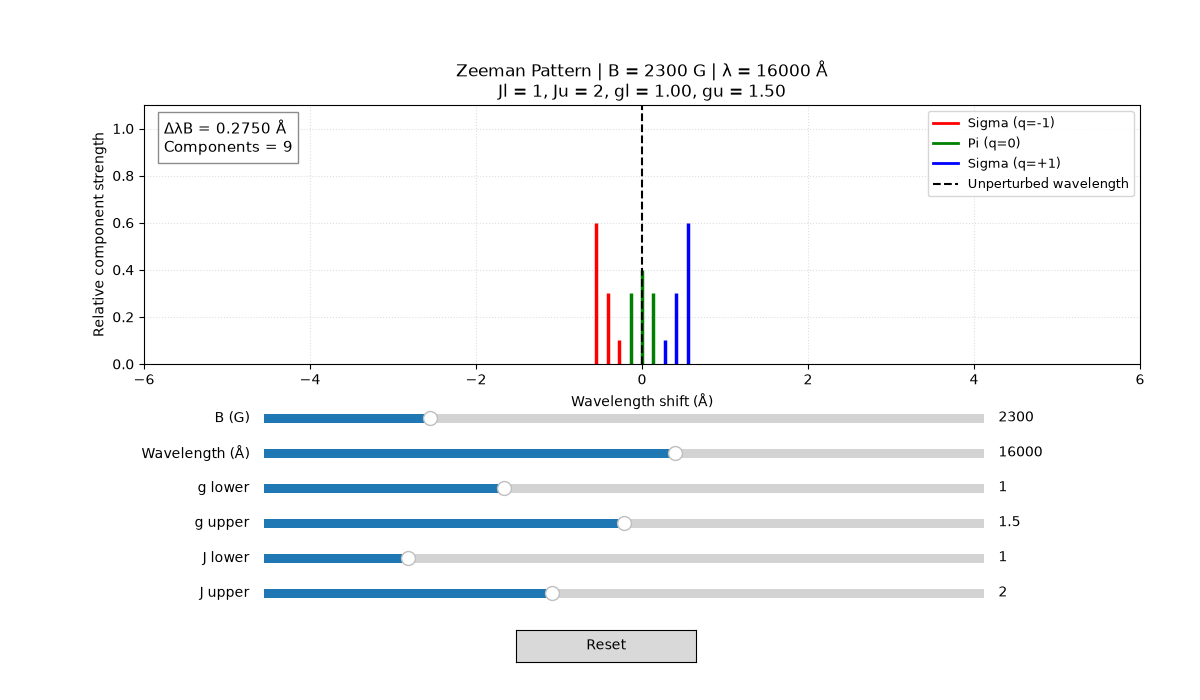

In [19]:

import numpy as np
import matplotlib.pyplot as plt

from matplotlib.widgets import Slider, Button
from matplotlib.lines import Line2D
from sympy import S
from sympy.physics.wigner import wigner_3j

# =====================================================
# 1. ZEEMAN PHYSICS
# =====================================================

def zeeman_splitting(B, wavelength):
    """
    B in Gauss
    wavelength in Angstrom
    Result in Angstrom
    """
    return 4.67e-13 * B * wavelength**2


def zeeman_pattern(Jl, Ju, gl, gu, B, wavelength):

    # Use integer 2J values to support half-integer J
    Jl2 = int(round(2 * Jl))
    Ju2 = int(round(2 * Ju))

    # Electric dipole selection rules
    if abs(Ju2 - Jl2) > 2 or (Jl2 == 0 and Ju2 == 0):
        return []

    if (Ju2 - Jl2) % 2 != 0:
        return []

    delta_B = zeeman_splitting(B, wavelength)

    components = []

    for ml2 in range(-Jl2, Jl2 + 1, 2):
        for mu2 in range(-Ju2, Ju2 + 1, 2):

            # q = Ml - Mu (the convention of Eq. 1.6)
            q2 = ml2 - mu2

            if q2 not in (-2, 0, 2):
                continue

            q = q2 // 2

            Ml = S(ml2) / 2
            Mu = S(mu2) / 2

            strength = 3 * float(
                wigner_3j(
                    S(Ju2) / 2,
                    S(Jl2) / 2,
                    S(1),
                    -Mu,
                    Ml,
                    -S(q)
                )**2
            )

            if strength <= 1e-12:
                continue

            # Equation (1.4)
            shift = (
                gl * float(Ml) - gu * float(Mu)
            ) * delta_B

            components.append({
                "shift": shift,
                "wavelength": wavelength + shift,
                "strength": strength,
                "q": q
            })

    return components


# =====================================================
# 2. INITIAL VALUES
# =====================================================

B0 = 2300
wavelength0 = 16000

gl0 = 1.0
gu0 = 1.5

Jl0 = 1
Ju0 = 2

colors = {
    -1: "red",
     0: "green",
     1: "blue"
}


# =====================================================
# 3. CREATE FIGURE
# =====================================================

fig, ax = plt.subplots(figsize=(12, 7))

# Reserve space for sliders
plt.subplots_adjust(
    left=0.12,
    right=0.95,
    top=0.85,
    bottom=0.48
)


# =====================================================
# 4. CREATE SLIDERS
# =====================================================

ax_B = plt.axes([0.22, 0.39, 0.60, 0.025])
ax_wl = plt.axes([0.22, 0.34, 0.60, 0.025])

ax_gl = plt.axes([0.22, 0.29, 0.60, 0.025])
ax_gu = plt.axes([0.22, 0.24, 0.60, 0.025])

ax_Jl = plt.axes([0.22, 0.19, 0.60, 0.025])
ax_Ju = plt.axes([0.22, 0.14, 0.60, 0.025])


slider_B = Slider(
    ax_B, "B (G)",
    0, 10000,
    valinit=B0,
    valstep=100
)

slider_wl = Slider(
    ax_wl, "Wavelength (Å)",
    4000, 25000,
    valinit=wavelength0,
    valstep=100
)

slider_gl = Slider(
    ax_gl, "g lower",
    0, 3,
    valinit=gl0,
    valstep=0.1
)

slider_gu = Slider(
    ax_gu, "g upper",
    0, 3,
    valinit=gu0,
    valstep=0.1
)

slider_Jl = Slider(
    ax_Jl, "J lower",
    0, 5,
    valinit=Jl0,
    valstep=0.5
)

slider_Ju = Slider(
    ax_Ju, "J upper",
    0, 5,
    valinit=Ju0,
    valstep=0.5
)


# =====================================================
# 5. LEGEND
# =====================================================

legend_elements = [
    Line2D(
        [0], [0], color="red", lw=2,
        label="Sigma (q=-1)"
    ),
    Line2D(
        [0], [0], color="green", lw=2,
        label="Pi (q=0)"
    ),
    Line2D(
        [0], [0], color="blue", lw=2,
        label="Sigma (q=+1)"
    ),
    Line2D(
        [0], [0], color="black",
        linestyle="--",
        label="Unperturbed wavelength"
    )
]


# =====================================================
# 6. UPDATE FUNCTION
# =====================================================

def update(val=None):

    B = slider_B.val
    wavelength = slider_wl.val

    gl = slider_gl.val
    gu = slider_gu.val

    Jl = slider_Jl.val
    Ju = slider_Ju.val

    ax.clear()

    components = zeeman_pattern(
        Jl, Ju, gl, gu, B, wavelength
    )

    delta_B = zeeman_splitting(B, wavelength)

    if len(components) == 0:
        ax.text(
            0.5, 0.5,
            "Forbidden electric-dipole transition",
            transform=ax.transAxes,
            ha="center",
            va="center",
            fontsize=14
        )

    else:
        for c in components:

            ax.vlines(
                c["shift"],
                0,
                c["strength"],
                color=colors[c["q"]],
                linewidth=2.5
            )

    ax.axvline(
        0,
        color="black",
        linestyle="--"
    )

    # Fixed horizontal scale for easier comparison
    ax.set_xlim(-6, 6)
    ax.set_ylim(0, 1.1)

    ax.set_xlabel("Wavelength shift (Å)")
    ax.set_ylabel("Relative component strength")

    ax.set_title(
        f"Zeeman Pattern | B = {B:.0f} G | "
        f"λ = {wavelength:.0f} Å\n"
        f"Jl = {Jl:g}, Ju = {Ju:g}, "
        f"gl = {gl:.2f}, gu = {gu:.2f}"
    )

    ax.grid(
        True,
        linestyle=":",
        alpha=0.4
    )

    ax.set_axisbelow(True)

    ax.legend(
        handles=legend_elements,
        loc="upper right",
        fontsize=9
    )

    # Show characteristic splitting
    ax.text(
        0.02, 0.95,
        f"ΔλB = {delta_B:.4f} Å\n"
        f"Components = {len(components)}",
        transform=ax.transAxes,
        va="top",
        fontsize=11,
        bbox=dict(
            facecolor="white",
            edgecolor="gray",
            alpha=0.9
        )
    )

    fig.canvas.draw_idle()


# =====================================================
# 7. CONNECT SLIDERS
# =====================================================

slider_B.on_changed(update)
slider_wl.on_changed(update)

slider_gl.on_changed(update)
slider_gu.on_changed(update)

slider_Jl.on_changed(update)
slider_Ju.on_changed(update)


# =====================================================
# 8. RESET BUTTON
# =====================================================

reset_ax = plt.axes([0.43, 0.055, 0.15, 0.045])

reset_button = Button(
    reset_ax,
    "Reset"
)

def reset(event):

    slider_B.reset()
    slider_wl.reset()

    slider_gl.reset()
    slider_gu.reset()

    slider_Jl.reset()
    slider_Ju.reset()

reset_button.on_clicked(reset)


# =====================================================
# 9. INITIAL PLOT
# =====================================================

update()

plt.show()
